# Bài tập lớn 2 - Gradient Domain Editing và Ghép ảnh toàn cảnh (Panoramic Photos - Image Stitching)

## Phần 1: Gradient Domain Editing

Chọn hai ảnh đầu vào:
- Ảnh nền (background image).
- Ảnh chứa đối tượng cần ghép (source image).
 
Xác định vùng đối tượng cần ghép từ ảnh nguồn (có thể bằng mask thủ công hoặc bán tự động).

Hiện thực kỹ thuật Gradient Domain Editing để ghép đối tượng từ ảnh nguồn vào ảnh nền sao cho kết quả tự nhiên về mặt ánh sáng và biên.

### 1.1. Chuẩn bị thư viện

In [12]:
%pip install numpy scipy opencv-python matplotlib ipykernel


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [13]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import splu

### 1.2. Chuẩn bị ảnh

(7424, 11136, 3)
(3568, 5352, 3)


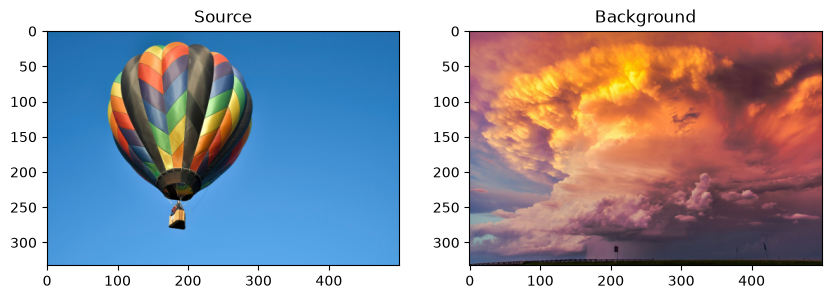

In [14]:
def load(path, max_side=500):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    print(img.shape)
    s = max_side / max(img.shape[:2])
    return cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img

src = load("../images/source.jpg")
dst = load("../images/background.jpg")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(src); ax[0].set_title("Source")
ax[1].imshow(dst); ax[1].set_title("Background")
for a in ax: a.axis("on")   # bật trục để đọc toạ độ vẽ mask
plt.show()

### 1.3. Xác định vùng đối tượng ghép

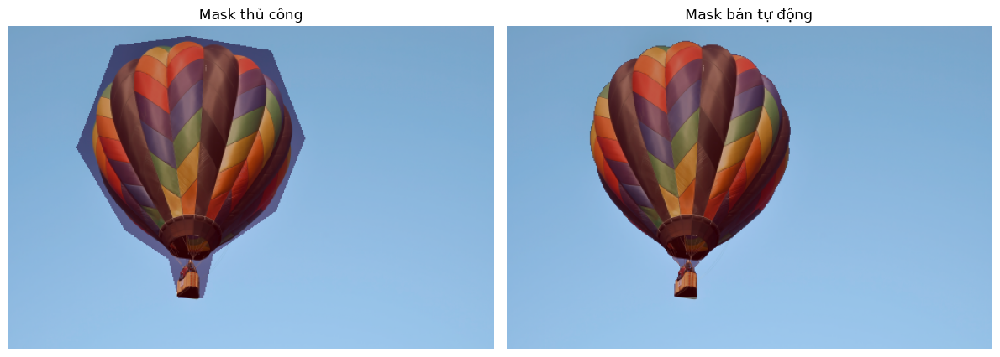

In [15]:
# 1. Tạo Mask thủ công từ các tọa độ đa giác
poly = np.array([
    [185, 10],   # Đỉnh trên cùng
    [270, 25],   # Vai phải trên
    [305, 115],  # Mép cực phải
    [275, 190],  # Hông phải dưới
    [210, 235],  # Cổ khinh khí cầu (phải)
    [200, 280],  # Đáy giỏ (phải)
    [175, 280],  # Đáy giỏ (trái)
    [165, 240],  # Cổ khinh khí cầu (trái)
    [120, 210],  # Hông trái dưới
    [70, 125],   # Mép cực trái
    [110, 20]    # Vai trái trên
], dtype=np.int32)
mask_manual = np.zeros(src.shape[:2], dtype=np.uint8)
cv2.fillPoly(mask_manual, [poly], 255)

# 2. Tạo Mask bán tự động bằng GrabCut
rect = (70, 10, 240, 270)  # (x, y, w, h)
gc_mask = np.zeros(src.shape[:2], dtype=np.uint8)
bgd, fgd = np.zeros((1, 65), np.float64), np.zeros((1, 65), np.float64)

cv2.grabCut(cv2.cvtColor(src, cv2.COLOR_RGB2BGR), gc_mask, rect, bgd, fgd, 5, cv2.GC_INIT_WITH_RECT)
mask_auto = np.where((gc_mask == 1) | (gc_mask == 3), 255, 0).astype(np.uint8)

# 3. Hiển thị
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(src)
ax[0].imshow(mask_manual, alpha=0.4, cmap="Reds")
ax[0].set_title("Mask thủ công")
ax[0].axis("off")

ax[1].imshow(src)
ax[1].imshow(mask_auto, alpha=0.4, cmap="Reds")
ax[1].set_title("Mask bán tự động")
ax[1].axis("off")

plt.tight_layout()
plt.show()

# 4. Chọn mask chính
mask = mask_manual

### 1.4. Cắt ROI và đặt vào vị trí trong ảnh nền

In [16]:
def crop_to_mask(src, mask, pad=1):
    ys, xs = np.nonzero(mask)
    y0, y1 = max(ys.min() - pad, 0), min(ys.max() + pad + 1, mask.shape[0])
    x0, x1 = max(xs.min() - pad, 0), min(xs.max() + pad + 1, mask.shape[1])
    return src[y0:y1, x0:x1], (mask[y0:y1, x0:x1] > 0)

src_c, mask_c = crop_to_mask(src, mask)
h, w = mask_c.shape
offset = (60, 200)   # (y, x) góc trên-trái của vùng ghép trong ảnh nền, chỉnh theo ý
assert offset[0] + h <= dst.shape[0] and offset[1] + w <= dst.shape[1], "Vượt ngoài ảnh nền"

### 1.5. Ghép trực tiếp

In [17]:
def direct_paste(src_c, mask_c, dst, offset):
    out = dst.copy()
    oy, ox = offset
    roi = out[oy:oy+h, ox:ox+w]
    roi[mask_c] = src_c[mask_c]
    return out

res_direct = direct_paste(src_c, mask_c, dst, offset)

### 1.6. Hiện thực giải thuật Poisson Blending

#### Poisson Blending

Tìm ảnh $f$ trong vùng ghép $\Omega$ sao cho gradient của $f$ gần gradient của ảnh nguồn $g$ nhất, và khớp với ảnh nền $f^*$ trên biên $\partial\Omega$:

$$
\min_f \iint_\Omega \left|\nabla f - \nabla g\right|^2 \quad \text{với} \quad f\big|_{\partial\Omega} = f^*\big|_{\partial\Omega}
$$

Nghiệm thỏa phương trình Poisson:

$$
\Delta f = \Delta g \ \text{ trong } \Omega, \qquad f\big|_{\partial\Omega} = f^*\big|_{\partial\Omega}
$$

Rời rạc hóa: với mỗi pixel $p \in \Omega$ ($N_p$ là 4 láng giềng của $p$):

$$
|N_p|\, f_p - \sum_{q \in N_p \cap \Omega} f_q = \sum_{q \in N_p \setminus \Omega} f^*_q + \sum_{q \in N_p} (g_p - g_q)
$$

Đây là hệ tuyến tính thưa $A\mathbf{f} = \mathbf{b}$, giải riêng cho từng kênh màu R, G, B.

In [18]:
def poisson_blend(src_c, mask_c, dst, offset, mixed=False):
    h, w = mask_c.shape
    oy, ox = offset
    roi = dst[oy:oy+h, ox:ox+w].astype(np.float64)
    s = src_c.astype(np.float64)

    ys, xs = np.nonzero(mask_c)
    n = len(ys)
    idx = -np.ones((h, w), int)
    idx[ys, xs] = np.arange(n)

    rows, cols, vals = [], [], []
    b = np.zeros((n, 3))
    for k, (y, x) in enumerate(zip(ys, xs)):
        cnt = 0
        for dy, dx in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            ny, nx = y + dy, x + dx
            if not (0 <= ny < h and 0 <= nx < w):
                continue
            cnt += 1
            g = s[y, x] - s[ny, nx]                    # gradient nguồn
            # if mixed:
            #     gd = roi[y, x] - roi[ny, nx]           # gradient nền
            #     g = np.where(np.abs(gd) > np.abs(g), gd, g)
            b[k] += g
            if mask_c[ny, nx]:
                rows.append(k); cols.append(idx[ny, nx]); vals.append(-1.0)
            else:
                b[k] += roi[ny, nx]                    # điều kiện biên Dirichlet
        rows.append(k); cols.append(k); vals.append(float(cnt))

    A = coo_matrix((vals, (rows, cols)), shape=(n, n)).tocsc()
    lu = splu(A)
    x = lu.solve(b)                                    # giải 3 kênh cùng lúc

    out = dst.copy()
    blended = roi.copy()
    blended[ys, xs] = x
    out[oy:oy+h, ox:ox+w] = np.clip(blended, 0, 255).astype(np.uint8)
    return out

res_poisson = poisson_blend(src_c, mask_c, dst, offset, mixed=False)

### 1.7. Sử dụng Poisson Blending có sẵn của OpenCV

In [19]:
cy, cx = offset[0] + h // 2, offset[1] + w // 2
m255 = (mask_c * 255).astype(np.uint8)
res_cv = cv2.seamlessClone(
    cv2.cvtColor(src_c, cv2.COLOR_RGB2BGR), cv2.cvtColor(dst, cv2.COLOR_RGB2BGR),
    m255, (cx, cy), cv2.NORMAL_CLONE)
res_cv = cv2.cvtColor(res_cv, cv2.COLOR_BGR2RGB)

### 1.8. Kết quả

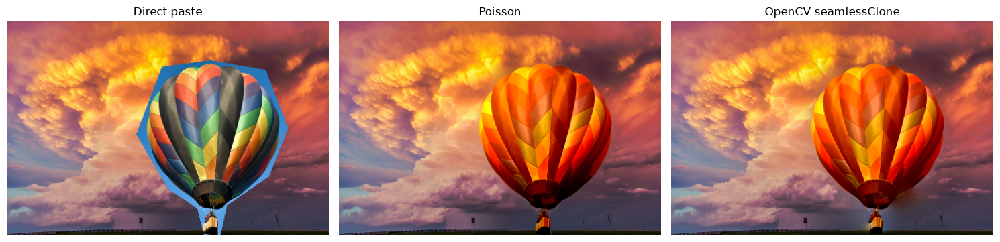

Direct paste           seam error = 86.74
Poisson                seam error = 0.23
OpenCV seamlessClone   seam error = 2.85


In [20]:
results = {"Direct paste": res_direct,
           "Poisson": res_poisson, "OpenCV seamlessClone": res_cv}

fig, ax = plt.subplots(1, 3, figsize=(15, 8))
for a, (name, im) in zip(ax.ravel(), results.items()):
    a.imshow(im); a.set_title(name); a.axis("off")
ax.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

# Độ chênh màu dọc đường biên: số nhỏ hơn nghĩa là ít lộ viền hơn
def seam_error(result, mask_c, dst, offset):
    oy, ox = offset
    k = np.ones((3, 3), np.uint8)
    ring = cv2.dilate(mask_c.astype(np.uint8), k) - cv2.erode(mask_c.astype(np.uint8), k)
    ring = ring.astype(bool)
    inside = result[oy:oy+h, ox:ox+w][mask_c & ring].astype(float)
    outside = dst[oy:oy+h, ox:ox+w][ring & ~mask_c].astype(float)
    return np.abs(inside.mean(0) - outside.mean(0)).mean() if len(outside) else np.nan

for name, im in results.items():
    print(f"{name:22s} seam error = {seam_error(im, mask_c, dst, offset):.2f}")

## Phần 2: Ghép ảnh toàn cảnh (Panoramic Photos - Image Stitching)
- Load và tiền xử lý ảnh (chuyển ảnh xám, chuẩn hóa kích thước nếu cần).
- Trích xuất đặc trưng (feature detection và description).
- So khớp đặc trưng giữa các cặp ảnh.
- Ước lượng phép biến đổi hình học (homography) giữa các ảnh.
- Căn chỉnh ảnh và ghép ảnh để tạo panorama.
- Xử lý vùng chồng lấn và biên ảnh (blending) ở mức cơ bản.

### 2.1. Chuẩn bị thư viện và tham số

In [3]:
import os, time, urllib.request
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESIZE_H   = 600     # chiều cao ảnh sau resize
NFEATURES  = 5000    # số keypoint tối đa
RATIO      = 0.75    # ngưỡng Lowe ratio test
RANSAC_THR = 4.0     # ngưỡng reprojection của RANSAC
MIN_INLIERS = 15     # số inlier tối thiểu để xem cặp ảnh là ghép được

rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

### 2.2. Pipeline

#### 2.2.1. Load và tiền xử lý ảnh (chuyển ảnh xám, chuẩn hoá kích thước)

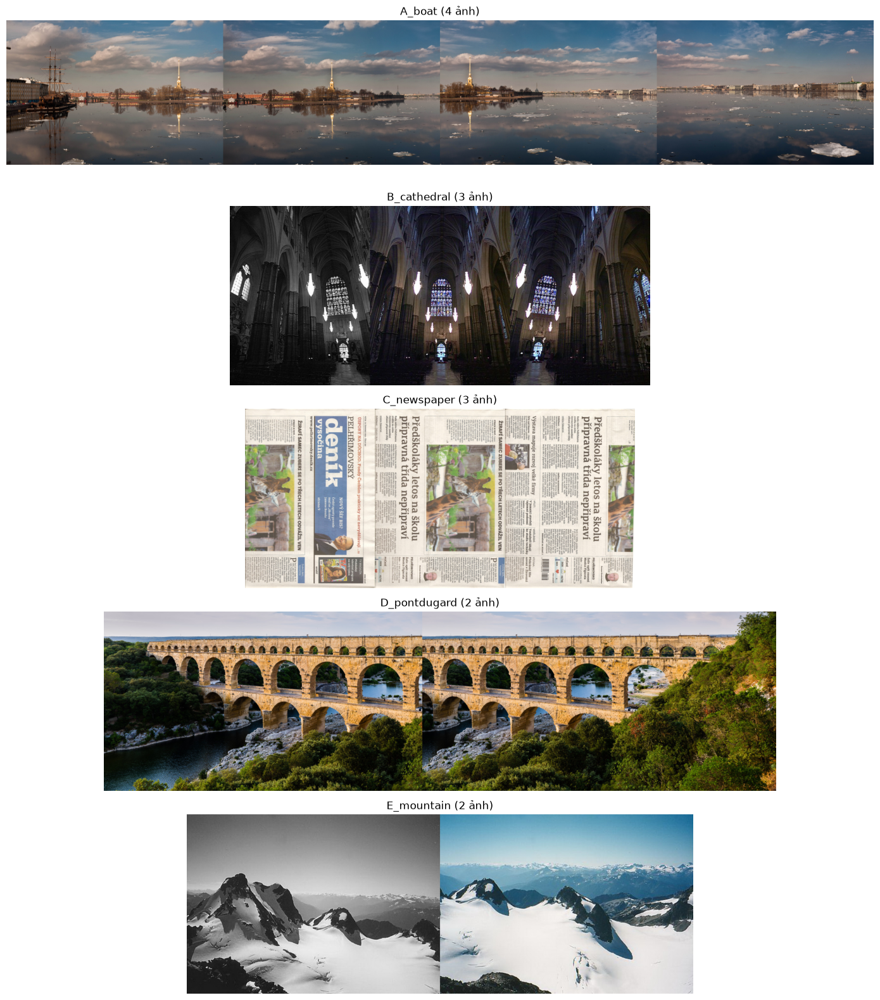

In [4]:
BASE = "https://raw.githubusercontent.com/opencv/opencv_extra/4.x/testdata/stitching/"
DATASETS = {                         
    "A_boat":       ["boat1.jpg", "boat2.jpg", "boat3.jpg", "boat4.jpg"],
    "B_cathedral":  ["a1.png", "a2.png", "a3.png"],
    "C_newspaper":  ["newspaper1.jpg", "newspaper2.jpg", "newspaper3.jpg"],
    "D_pontdugard": ["s1.jpg", "s2.jpg"],
    "E_mountain":   ["b1.png", "b2.png"],
}
IMG_DIR = "../images"
os.makedirs(IMG_DIR, exist_ok=True)
imgs, grays = {}, {}
for name, files in DATASETS.items():
    ims = []
    for f in files:
        f_path = os.path.join(IMG_DIR, f)
        if not os.path.exists(f_path):
            urllib.request.urlretrieve(BASE + f, f_path)
        im = cv2.imread(f_path)
        s = RESIZE_H / im.shape[0]
        ims.append(cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA))
    imgs[name] = ims
    grays[name] = [cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) for im in ims]

fig, axs = plt.subplots(len(imgs), 1, figsize=(14, 3.2 * len(imgs)))
for ax, (name, ims) in zip(axs, imgs.items()):
    ax.imshow(rgb(np.hstack(ims))); ax.set_title(f"{name} ({len(ims)} ảnh)"); ax.axis("off")
plt.tight_layout(); plt.show()

#### 2.2.2. Trích xuất đặc trưng (SIFT, ORB)

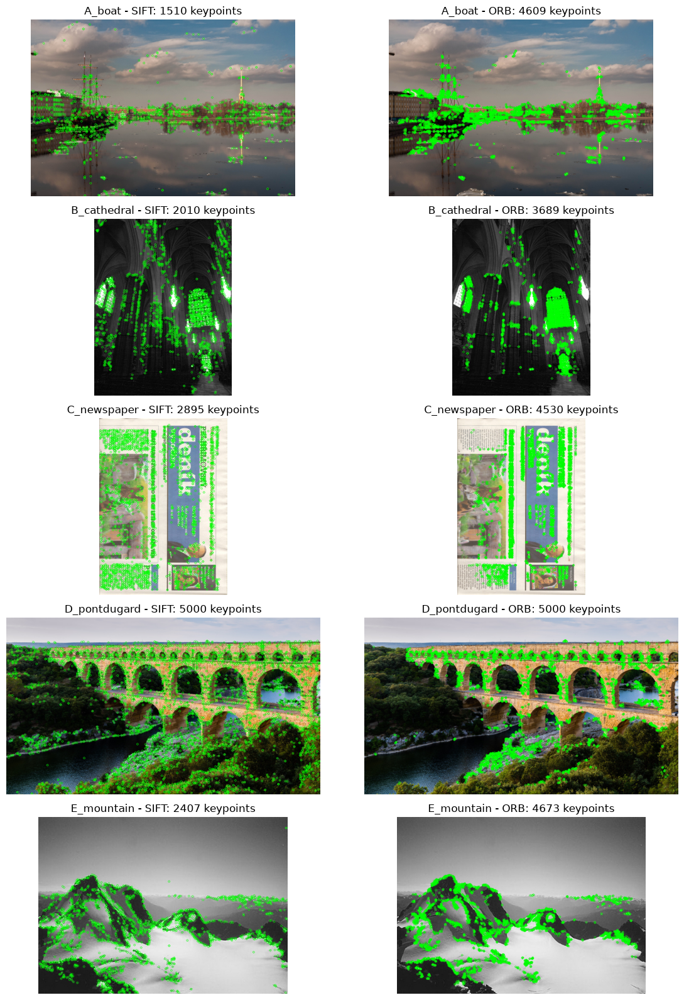

In [5]:
METHODS = {
    "SIFT": (cv2.SIFT_create(nfeatures=NFEATURES), cv2.NORM_L2),
    "ORB":  (cv2.ORB_create(nfeatures=NFEATURES),  cv2.NORM_HAMMING),
}
feats, t_extract = {}, {}        
for name in imgs:
    for m, (det, _) in METHODS.items():
        t = time.perf_counter()
        feats[(name, m)] = [det.detectAndCompute(g, None) for g in grays[name]]
        t_extract[(name, m)] = time.perf_counter() - t

fig, axs = plt.subplots(len(imgs), 2, figsize=(12, 3.2 * len(imgs)))
for r, name in enumerate(imgs):
    for c, m in enumerate(METHODS):
        kp = feats[(name, m)][0][0]
        axs[r, c].imshow(rgb(cv2.drawKeypoints(imgs[name][0], kp, None, color=(0, 255, 0))))
        axs[r, c].set_title(f"{name} - {m}: {len(kp)} keypoints"); axs[r, c].axis("off")
plt.tight_layout(); plt.show()

#### 2.2.3. So khớp đặc trưng giữa các cặp ảnh kề nhau (kNN + ratio test)

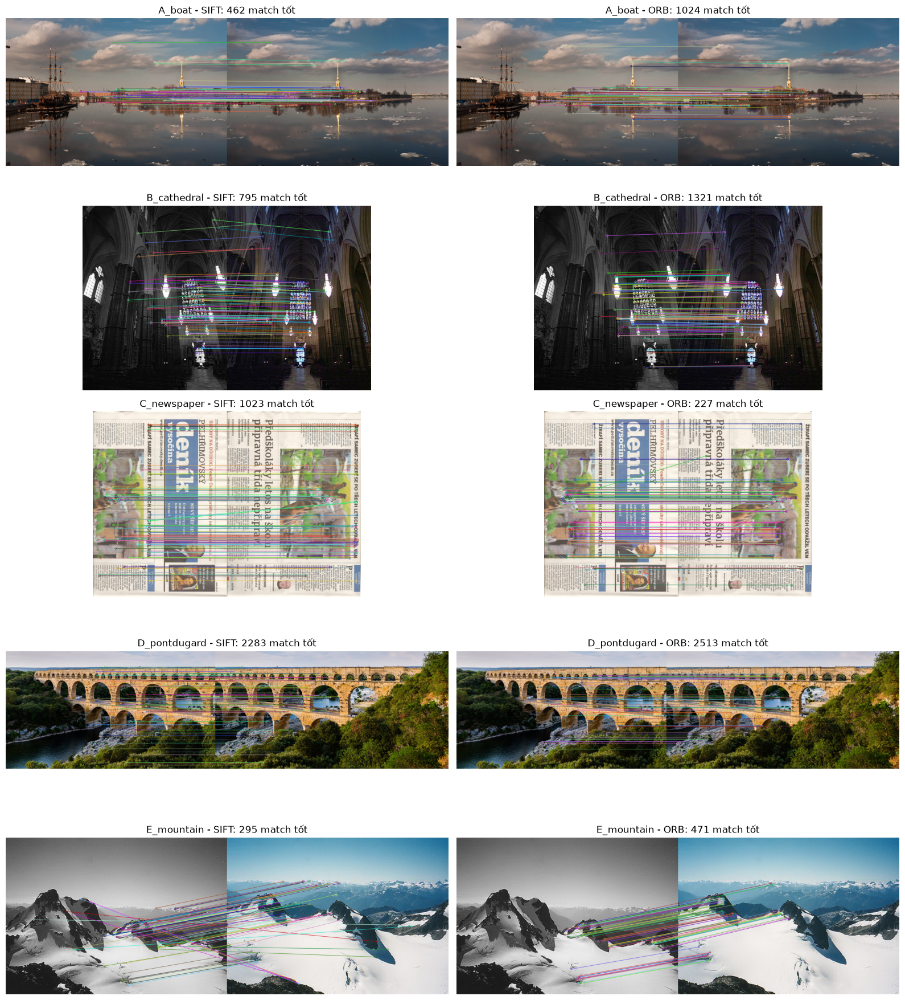

In [6]:
matches = {}                        
for (name, m), f in feats.items():
    bf = cv2.BFMatcher(METHODS[m][1])
    matches[(name, m)] = []
    for i in range(len(f) - 1):
        knn = bf.knnMatch(f[i][1], f[i + 1][1], k=2)
        good = [p[0] for p in knn if len(p) == 2 and p[0].distance < RATIO * p[1].distance]
        matches[(name, m)].append(sorted(good, key=lambda g: g.distance))

# 100 match tốt nhất của cặp ảnh đầu tiên (ảnh 1 - ảnh 2)
fig, axs = plt.subplots(len(imgs), 2, figsize=(16, 3.6 * len(imgs)))
for r, name in enumerate(imgs):
    for c, m in enumerate(METHODS):
        f, good = feats[(name, m)], matches[(name, m)][0]
        vis = cv2.drawMatches(imgs[name][0], f[0][0], imgs[name][1], f[1][0], good[:100], None,
                              flags=cv2.DRAW_MATCHES_FLAGS_NOT_DRAW_SINGLE_POINTS)
        axs[r, c].imshow(rgb(vis)); axs[r, c].set_title(f"{name} - {m}: {len(good)} match tốt"); axs[r, c].axis("off")
plt.tight_layout(); plt.show()

#### 2.2.4. Ước lượng phép biến đổi hình học (homography) giữa các ảnh kết hợp RANSAC

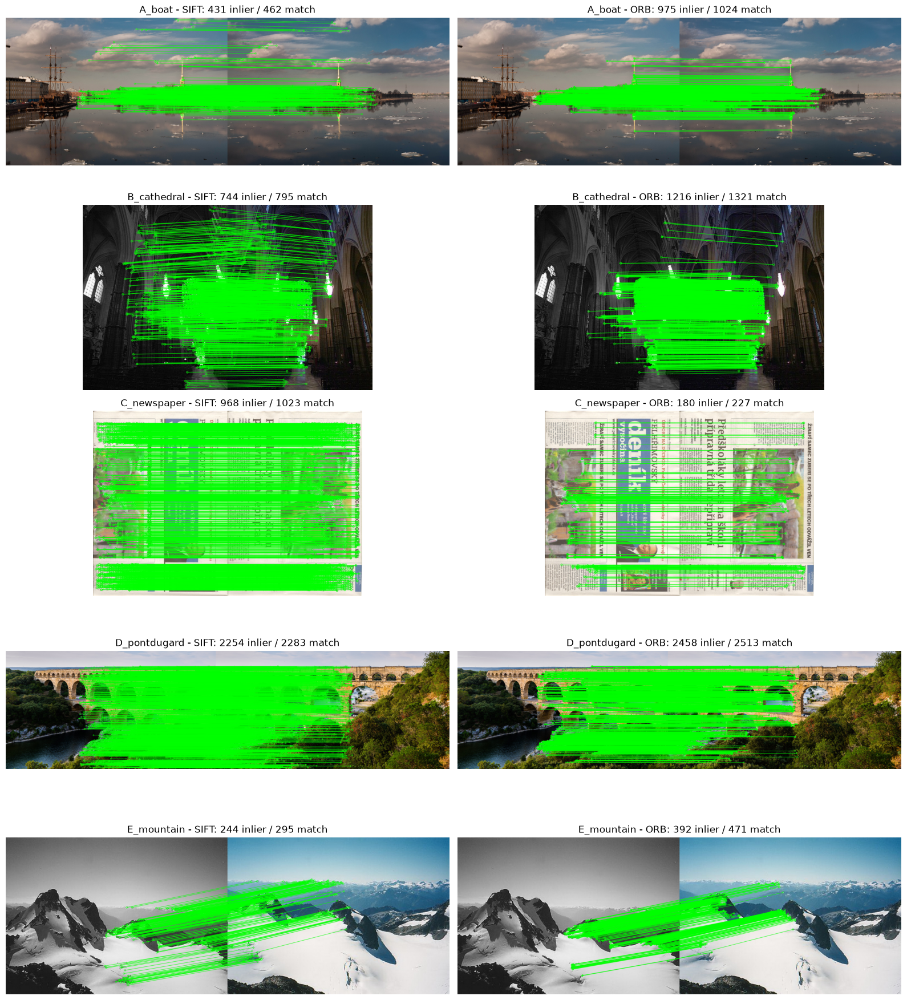

,dataset,method,pair,n_kp,n_good,n_inliers,inlier_ratio,reproj_err_px,status
0,A_boat,SIFT,1-2,1510/1064,462,431,0.933,0.321,ok
1,A_boat,SIFT,2-3,1064/1070,383,319,0.833,0.307,ok
2,A_boat,SIFT,3-4,1070/1106,215,193,0.898,0.587,ok
3,A_boat,ORB,1-2,4609/4261,1024,975,0.952,1.020,ok
4,A_boat,ORB,2-3,4261/4183,1240,1108,0.894,1.220,ok
5,A_boat,ORB,3-4,4183/4181,650,596,0.917,0.943,ok
6,B_cathedral,SIFT,1-2,2010/2360,795,744,0.936,0.837,ok
7,B_cathedral,SIFT,2-3,2360/2366,886,822,0.928,0.966,ok
8,B_cathedral,ORB,1-2,3689/3837,1321,1216,0.921,1.007,ok
9,B_cathedral,ORB,2-3,3837/3760,1459,1369,0.938,1.083,ok


In [7]:
H_pair, inl_mask, rows = {}, {}, [] 
for (name, m), res in matches.items():
    f = feats[(name, m)]; H_pair[(name, m)] = []
    for i, good in enumerate(res):
        H, inl, err = None, np.zeros(len(good), bool), np.nan
        if len(good) >= 4:
            p1 = np.float32([f[i][0][g.queryIdx].pt for g in good]).reshape(-1, 1, 2)
            p2 = np.float32([f[i + 1][0][g.trainIdx].pt for g in good]).reshape(-1, 1, 2)
            H, mask = cv2.findHomography(p1, p2, cv2.RANSAC, RANSAC_THR)
            if H is not None:
                inl = mask.ravel().astype(bool)
                err = np.linalg.norm(cv2.perspectiveTransform(p1[inl], H) - p2[inl], axis=2).mean()
        ok = H is not None and inl.sum() >= MIN_INLIERS
        H_pair[(name, m)].append(H if ok else None)
        inl_mask[(name, m, i)] = inl
        rows.append(dict(dataset=name, method=m, pair=f"{i+1}-{i+2}", n_kp=f"{len(f[i][0])}/{len(f[i+1][0])}",
                         n_good=len(good), n_inliers=int(inl.sum()), inlier_ratio=round(inl.sum() / max(len(good), 1), 3),
                         reproj_err_px=round(err, 3), status="ok" if ok else "FAILED"))
df_pairs = pd.DataFrame(rows)

# Match inlier của cặp ảnh đầu tiên
fig, axs = plt.subplots(len(imgs), 2, figsize=(16, 3.6 * len(imgs)))
for r, name in enumerate(imgs):
    for c, m in enumerate(METHODS):
        f, good, inl = feats[(name, m)], matches[(name, m)][0], inl_mask[(name, m, 0)]
        vis = cv2.drawMatches(imgs[name][0], f[0][0], imgs[name][1], f[1][0], good, None,
                              matchesMask=inl.astype(int).tolist(), matchColor=(0, 255, 0),
                              flags=cv2.DRAW_MATCHES_FLAGS_NOT_DRAW_SINGLE_POINTS)
        axs[r, c].imshow(rgb(vis)); axs[r, c].set_title(f"{name} - {m}: {inl.sum()} inlier / {len(good)} match"); axs[r, c].axis("off")
plt.tight_layout(); plt.show()
df_pairs

#### 2.2.5. Căn chỉnh ảnh về ảnh giữa và warp lên canvas chung

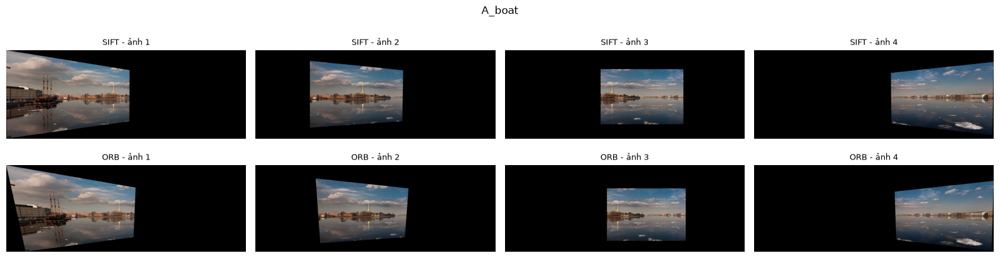

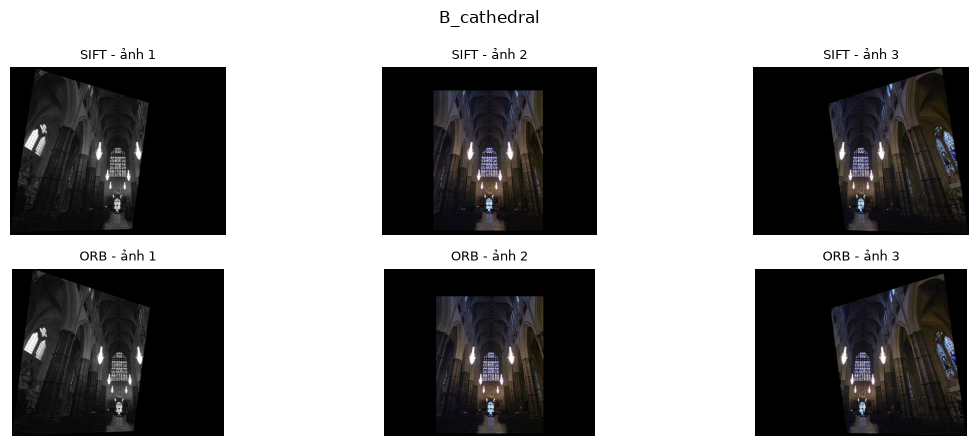

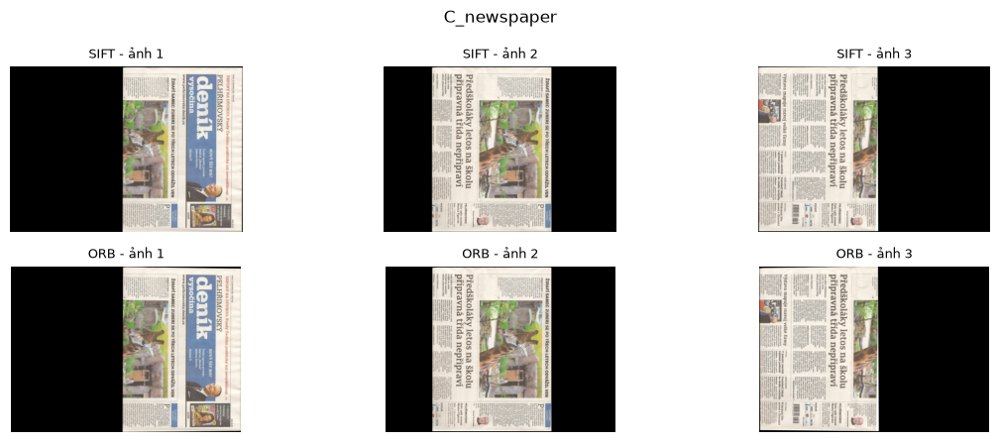

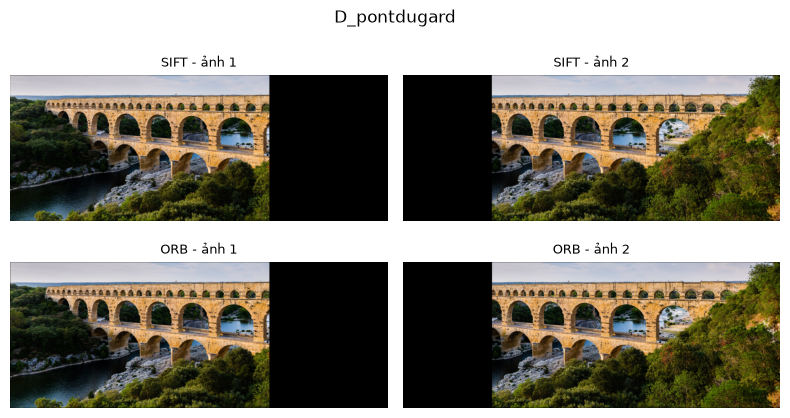

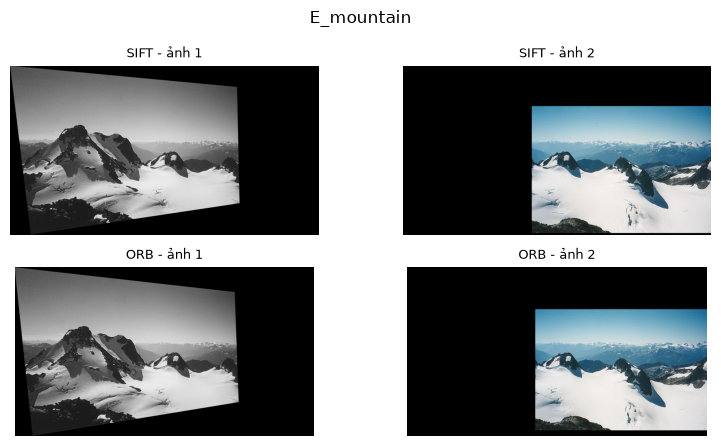

In [11]:
scene = {}                           
for (name, m), Hl in H_pair.items():
    if any(H is None for H in Hl):
        continue                     # có cặp ảnh ghép thất bại -> không dựng panorama
    ims, n = imgs[name], len(imgs[name]); ref = n // 2
    Hs = []
    for i in range(n):               # H: ảnh i -> ảnh tham chiếu (ảnh giữa)
        H = np.eye(3)
        if i < ref:
            for j in range(i, ref): H = Hl[j] @ H
        else:
            for j in range(ref, i): H = H @ np.linalg.inv(Hl[j])
        Hs.append(H / H[2, 2])
    pts = np.concatenate([cv2.perspectiveTransform(np.float32([[0, 0], [im.shape[1], 0], [im.shape[1], im.shape[0]], [0, im.shape[0]]]).reshape(-1, 1, 2), H).reshape(-1, 2)
                          for im, H in zip(ims, Hs)])
    if not np.isfinite(pts).all() or np.prod(pts.max(0) - pts.min(0)) > 25e6:
        print(f"{name} - {m}: canvas bất thường, bỏ qua"); continue
    x0, y0 = np.floor(pts.min(0)).astype(int); x1, y1 = np.ceil(pts.max(0)).astype(int)
    T = np.array([[1, 0, -x0], [0, 1, -y0], [0, 0, 1]], float)       # tịnh tiến để không có tọa độ âm
    size = (int(x1 - x0), int(y1 - y0))
    warped = [cv2.warpPerspective(im, T @ H, size) for im, H in zip(ims, Hs)]
    valid = [cv2.warpPerspective(np.full(im.shape[:2], 255, np.uint8), T @ H, size, flags=cv2.INTER_NEAREST) for im, H in zip(ims, Hs)]
    scene[(name, m)] = dict(warped=warped, valid=valid, size=size)

for name in imgs:
    n = len(imgs[name]); fig, axs = plt.subplots(2, n, figsize=(4 * n, 4.5), squeeze=False)
    for r, m in enumerate(METHODS):
        for c in range(n):
            axs[r, c].axis("off")
            if (name, m) in scene: axs[r, c].imshow(rgb(scene[(name, m)]["warped"][c])); axs[r, c].set_title(f"{m} - ảnh {c+1}", fontsize=9)
            else: axs[r, c].text(0.5, 0.5, f"{m}\nFAILED", ha="center", va="center", color="red", transform=axs[r, c].transAxes)
    fig.suptitle(name); plt.tight_layout(); plt.show()

#### 2.2.6. Ghép ảnh và blending vùng chồng lấn bằng feathering

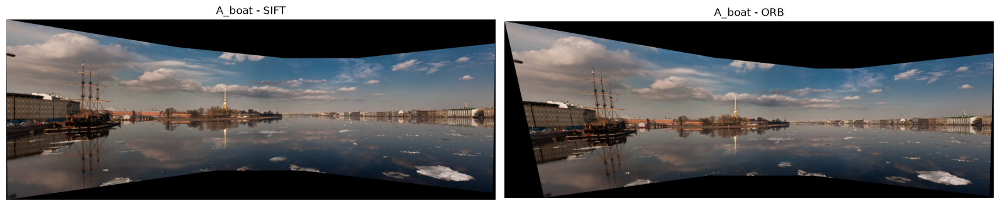

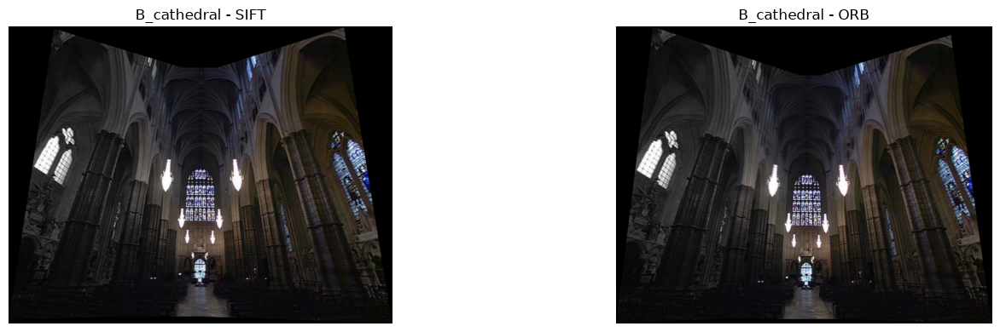

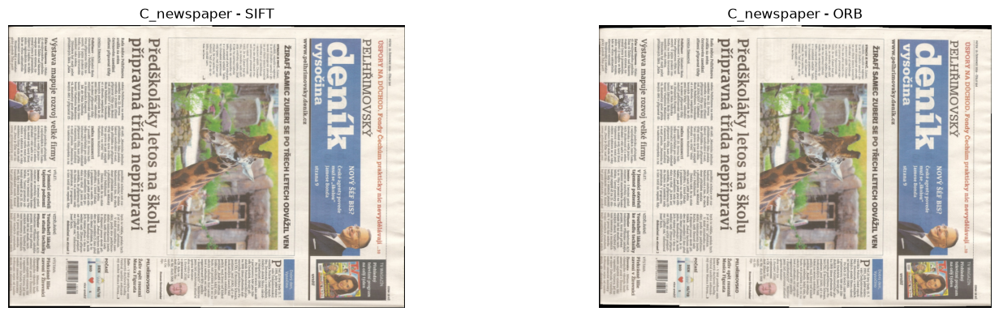

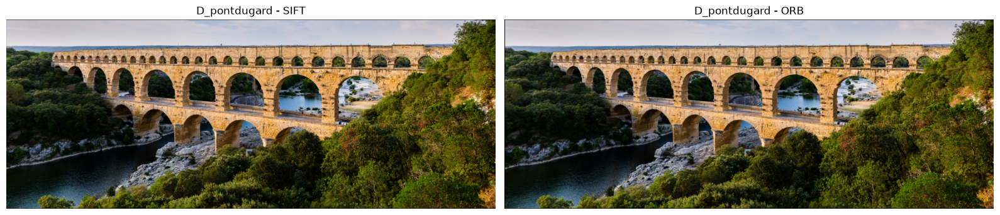

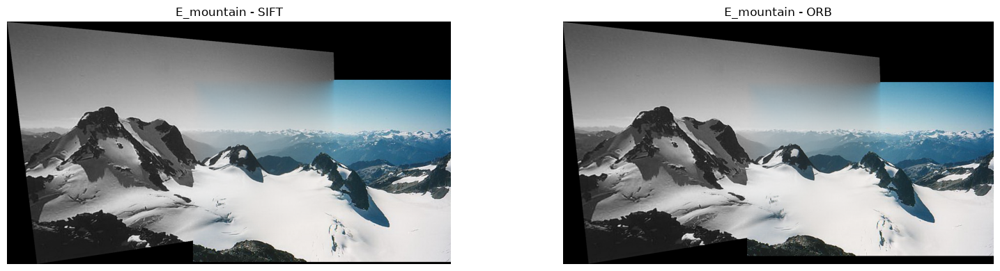

In [ ]:
OUT_DIR = "../results"
os.makedirs(OUT_DIR, exist_ok=True)
pano = {}
for (name, m), s in scene.items():
    w = [cv2.distanceTransform(v, cv2.DIST_L2, 3) for v in s["valid"]]      # trọng số = khoảng cách tới biên ảnh
    acc = sum(im.astype(np.float32) * d[..., None] for im, d in zip(s["warped"], w))
    res_pano = (acc / np.maximum(sum(w), 1e-6)[..., None]).astype(np.uint8)
    pano[(name, m)] = res_pano
    cv2.imwrite(os.path.join(OUT_DIR, f"{name}_{m}_panorama.jpg"), res_pano)

# Panorama của từng bộ ảnh
for name in imgs:
    fig, axs = plt.subplots(1, 2, figsize=(16, 4))
    for ax, m in zip(axs, METHODS):
        ax.axis("off")
        if (name, m) in pano: ax.imshow(rgb(pano[(name, m)])); ax.set_title(f"{name} - {m}")
        else: ax.text(0.5, 0.5, f"{m}: FAILED", ha="center", va="center", color="red", fontsize=16, transform=ax.transAxes)
    plt.tight_layout(); plt.show()

### 2.3. Bảng tổng hợp SIFT và ORB

In [10]:
df_pairs["_ok"] = df_pairs.status == "ok"
summary = df_pairs.groupby(["dataset", "method"]).agg(
    n_good=("n_good", "sum"), n_inliers=("n_inliers", "sum"),
    inlier_ratio=("inlier_ratio", "mean"), reproj_err_px=("reproj_err_px", "mean"),
    pairs_ok=("_ok", "sum"), n_pairs=("_ok", "size")).round(3).reset_index()
summary["t_extract_s"] = [round(t_extract[(d, m)], 3) for d, m in zip(summary.dataset, summary.method)]
summary["panorama"] = [f"OK {scene[(d, m)]['size'][0]}x{scene[(d, m)]['size'][1]}" if (d, m) in pano else "FAILED"
                       for d, m in zip(summary.dataset, summary.method)]
summary

,dataset,method,n_good,n_inliers,inlier_ratio,reproj_err_px,pairs_ok,n_pairs,t_extract_s,panorama
0,A_boat,ORB,2914,2679,0.921,1.061,3,3,0.341,OK 2738x991
1,A_boat,SIFT,1060,943,0.888,0.405,3,3,0.144,OK 2606x963
2,B_cathedral,ORB,2780,2585,0.930,1.045,2,2,0.021,OK 924x731
3,B_cathedral,SIFT,1681,1566,0.932,0.902,2,2,0.066,OK 924x716
4,C_newspaper,ORB,1618,1460,0.856,0.903,2,2,0.029,OK 841x607
5,C_newspaper,SIFT,2419,2236,0.927,0.214,2,2,0.109,OK 848x605
6,D_pontdugard,ORB,2513,2458,0.978,0.863,1,1,0.036,OK 1556x602
7,D_pontdugard,SIFT,2283,2254,0.987,0.133,1,1,0.145,OK 1555x602
8,E_mountain,ORB,471,392,0.832,1.343,1,1,0.019,OK 1482x836
9,E_mountain,SIFT,295,244,0.827,1.062,1,1,0.060,OK 1459x798
